# Problem 2 extension — Minimum sensors for a target error

Binary budget search with the existing **VND + Beam Search and Greedy**, evaluated using the actual overall sequential error including off-pair outcomes. Targets are $\epsilon\in\{0.1,0.2,0.3,0.4,0.5\}$. Each returned allocation and decision tree is explicitly verified to satisfy its target.

The result is the **smallest verified feasible budget visited by the heuristic budget search**, not a globally optimal minimum. Heuristic feasibility need not be monotone in the sensor budget.

Both modes reuse the existing Extended datasets. Before the sensor-bound cutoff, **test** selects 180 instances per dimension and **full** selects 2,160. The default cutoff retains 2,155 1D and 2,134 2D full-study instances. No dataset is regenerated.


In [ ]:
from pathlib import Path
import sys, importlib, importlib.util
from IPython.display import display, Markdown

candidates = []
for parent in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
    candidates.extend([parent, parent/'problem-2-dual', parent/'problem-2-min-error-seq/problem-2-dual'])
HERE = next(p for p in candidates if (p/'dual_search.py').is_file())
sys.path.insert(0, str(HERE))
import dual_search
importlib.reload(dual_search)
import greedy_comparison
importlib.reload(greedy_comparison)
import budget_limited
importlib.reload(budget_limited)
spec = importlib.util.spec_from_file_location('dual_reporting', HERE/'reporting.py')
dual_reporting = importlib.util.module_from_spec(spec)
spec.loader.exec_module(dual_reporting)

RUN_MODE = 'full'  # Applies when RUN_ANALYSIS=True; saved reports use their metadata.
RUN_ANALYSIS = False
SAVED_RESULTS = HERE/'results/test/e42f02f6d2a5d551'
RESUME = True
TARGET_ERRORS = (0.1, 0.2, 0.3, 0.4, 0.5)
BEAM_WIDTH = 3
MAX_ITERATIONS = 30
TIME_LIMIT_SECONDS = None  # Optional positive per-budget heuristic time limit.
BOOTSTRAP_RESAMPLES = 2000
BOOTSTRAP_SEED = 20261015

MAX_SENSOR_BOUND = 5000


## Budget search and feasibility

The saved $N_{\min}^{\mathrm{seq}}$ is the initial upper bound. The original Problem 1 solver reconstructs its perfect allocation and covering pair-test locations. A deterministic elimination tree is built from those locations and verified with the full sequential evaluator; the saved bound must match the reconstructed minimum.

For each target, start at `low=0`, `high=N_min_seq`. Independently evaluate each method at its bisection midpoint, retaining a feasible allocation/tree and lowering `high` when the actual error is at most the target; otherwise raise `low`. Stop when `high-low <= 1`. Zero-budget guessing is checked explicitly. No sensor-budget cap of 50 is applied to this search: its upper bound is the existing sequential minimum.

A timeout retains the last verified feasible solution and is marked incomplete; it is not evidence of infeasibility. Resume retries that budget. The complete allocation and tree are saved in the results, together with a trace of evaluated budgets.


In [2]:
if RUN_ANALYSIS:
    REPORT_MODE = RUN_MODE
    REPORT_TARGET_ERRORS = TARGET_ERRORS
    solutions, failures, OUTPUT = budget_limited.run_comparison(
        RUN_MODE, targets=TARGET_ERRORS, beam_width=BEAM_WIDTH,
        max_sensor_bound=MAX_SENSOR_BOUND,
        max_iterations=MAX_ITERATIONS, time_limit=TIME_LIMIT_SECONDS,
        resume=RESUME, run=True,
    )
else:
    import json
    OUTPUT = Path(SAVED_RESULTS)
    saved_info = json.loads((OUTPUT/'run_info.json').read_text())
    REPORT_MODE = saved_info['mode']
    REPORT_TARGET_ERRORS = tuple(saved_info['targets'])
    print(f'Loading saved {REPORT_MODE} results; no searches will run.')
    if REPORT_MODE != RUN_MODE or REPORT_TARGET_ERRORS != TARGET_ERRORS:
        print('RUN_MODE and TARGET_ERRORS apply only when RUN_ANALYSIS=True.')
    solutions = json.loads((OUTPUT/'solutions.json').read_text())
    failures = json.loads((OUTPUT/'failures.json').read_text())
import json
skipped_path = OUTPUT/'skipped.json'
skipped = json.loads(skipped_path.read_text()) if skipped_path.exists() else []
print('Skipped instances:', len(skipped))
assert all(r['verified_feasible'] and r['actual_error'] <= r['epsilon'] for r in solutions)
assert all(sum(r['allocation']) == r['N'] <= r['N_min_seq'] for r in solutions)
print('Report mode:', REPORT_MODE)
print('Report targets:', REPORT_TARGET_ERRORS)
print('Verified solutions:', len(solutions))
print('Failed instances:', len(failures))
print('Results:', OUTPUT)

if not any(r.get('method') == 'greedy' for r in solutions):
    print('Greedy results are not saved yet. Set RUN_ANALYSIS=True to compute them; matching VND results are reused.')


Upper-bound cutoff: 5000; included 4320/4320; skipped 0. Existing search checkpoints are reused.
vnd_beam | Snapshot 1/4320 | 1D | gaussian | K=3, M=2
vnd_beam | Snapshot 2/4320 | 1D | gaussian | K=3, M=2
vnd_beam | Snapshot 3/4320 | 1D | gaussian | K=3, M=2
vnd_beam | Snapshot 4/4320 | 1D | gaussian | K=3, M=2
vnd_beam | Snapshot 5/4320 | 1D | gaussian | K=3, M=2
vnd_beam | Snapshot 6/4320 | 1D | gaussian | K=3, M=2
vnd_beam | Snapshot 7/4320 | 1D | gaussian | K=3, M=2
vnd_beam | Snapshot 8/4320 | 1D | gaussian | K=3, M=2
vnd_beam | Snapshot 9/4320 | 1D | gaussian | K=3, M=2
vnd_beam | Snapshot 10/4320 | 1D | gaussian | K=3, M=2
vnd_beam | Snapshot 11/4320 | 1D | gaussian | K=3, M=3
vnd_beam | Snapshot 12/4320 | 1D | gaussian | K=3, M=3
vnd_beam | Snapshot 13/4320 | 1D | gaussian | K=3, M=3
vnd_beam | Snapshot 14/4320 | 1D | gaussian | K=3, M=3
vnd_beam | Snapshot 15/4320 | 1D | gaussian | K=3, M=3
vnd_beam | Snapshot 16/4320 | 1D | gaussian | K=3, M=3
vnd_beam | Snapshot 17/4320 | 1D

## Required sensors versus target error

Curves use instances with completed searches for **both methods at all five targets** once both methods have results, preserving paired comparisons. The green line shows VND + Beam Search and the red dashed line shows Greedy. Both show median sensor counts; shading spans the 25th–75th percentiles (interquartile range). The band describes variability across instances, not a confidence interval. No instances are removed for having extreme sensor counts. Mean counts and their 95% bootstrap confidence intervals remain in the numerical summary, alongside the median and quartiles.

Runtime includes perfect-allocation reconstruction/verification plus target-specific budget search and actual-error evaluation. Perfect setup is shared computationally but charged once per target to represent an independent target run. Accumulated measured times are retained on resume. Both components are shown separately.


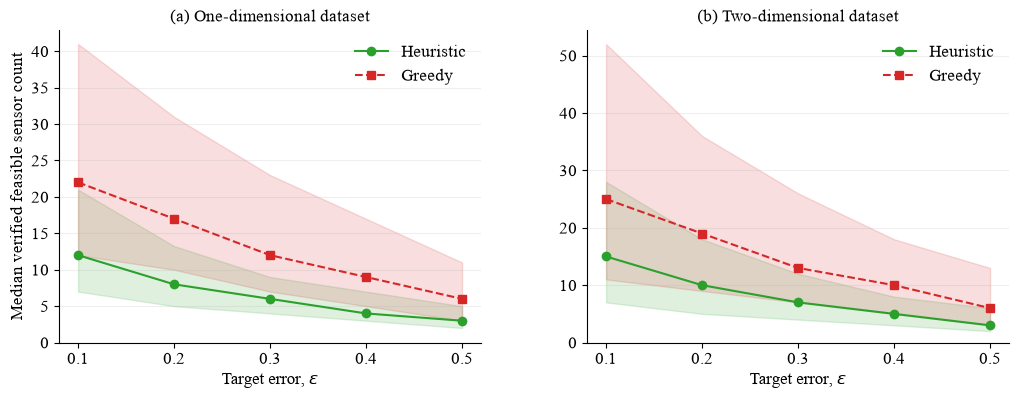

### Target-error summary

| dimension | method | epsilon | instances | median_required_sensors | q25_required_sensors | q75_required_sensors | mean_required_sensors | ci_low | ci_high | mean_runtime_seconds | mean_perfect_setup_seconds | mean_budget_search_seconds | mean_achieved_error | max_achieved_error | all_feasible |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1D | vnd_beam | 0.1 | 2160 | 12 | 7 | 21 | 17.0819 | 16.4059 | 17.8426 | 2.77126 | 0.00578489 | 2.76548 | 0.0818002 | 0.0999986 | True |
| 1D | vnd_beam | 0.2 | 2160 | 8 | 5 | 13.25 | 9.98843 | 9.75416 | 10.2436 | 2.66118 | 0.00578489 | 2.65539 | 0.169723 | 0.199989 | True |
| 1D | vnd_beam | 0.3 | 2160 | 6 | 4 | 9 | 6.86944 | 6.73008 | 7.01205 | 2.6652 | 0.00578489 | 2.65941 | 0.257293 | 0.299999 | True |
| 1D | vnd_beam | 0.4 | 2160 | 4 | 3 | 7 | 4.86991 | 4.77823 | 4.96574 | 2.64528 | 0.00578489 | 2.63949 | 0.3486 | 0.399999 | True |
| 1D | vnd_beam | 0.5 | 2160 | 3 | 2 | 5 | 3.36806 | 3.30509 | 3.43104 | 2.61389 | 0.00578489 | 2.6081 | 0.442613 | 0.499972 | True |
| 1D | greedy | 0.1 | 2160 | 22 | 12 | 41 | 31.3968 | 30.2844 | 32.5534 | 0.0703107 | 0.00578489 | 0.0645258 | 0.0320127 | 0.099998 | True |
| 1D | greedy | 0.2 | 2160 | 17 | 10 | 31 | 23.1403 | 22.5017 | 23.8125 | 0.0643774 | 0.00578489 | 0.0585925 | 0.120587 | 0.199996 | True |
| 1D | greedy | 0.3 | 2160 | 12 | 7 | 23 | 17.1704 | 16.7139 | 17.6491 | 0.0598945 | 0.00578489 | 0.0541096 | 0.241332 | 0.299996 | True |
| 1D | greedy | 0.4 | 2160 | 9 | 5 | 17 | 12.4801 | 12.1338 | 12.8334 | 0.0556683 | 0.00578489 | 0.0498834 | 0.353018 | 0.399985 | True |
| 1D | greedy | 0.5 | 2160 | 6 | 3 | 11 | 8.54352 | 8.27497 | 8.81343 | 0.0531596 | 0.00578489 | 0.0473747 | 0.451932 | 0.499976 | True |
| 2D | vnd_beam | 0.1 | 2160 | 15 | 7 | 28 | 22.0944 | 21.1203 | 23.1071 | 2.35356 | 0.00753035 | 2.34603 | 0.0817569 | 0.0999979 | True |
| 2D | vnd_beam | 0.2 | 2160 | 10 | 5 | 18 | 12.7787 | 12.4093 | 13.1871 | 2.30182 | 0.00753035 | 2.29429 | 0.17062 | 0.199992 | True |
| 2D | vnd_beam | 0.3 | 2160 | 7 | 4 | 12 | 8.61435 | 8.39304 | 8.84917 | 2.23476 | 0.00753035 | 2.22723 | 0.258683 | 0.299982 | True |
| 2D | vnd_beam | 0.4 | 2160 | 5 | 3 | 8 | 5.9125 | 5.78053 | 6.05093 | 2.22619 | 0.00753035 | 2.21866 | 0.352303 | 0.399976 | True |
| 2D | vnd_beam | 0.5 | 2160 | 3 | 2 | 6 | 4.03102 | 3.94536 | 4.11946 | 2.22766 | 0.00753035 | 2.22013 | 0.447649 | 0.499983 | True |
| 2D | greedy | 0.1 | 2160 | 25 | 11 | 52 | 36.7796 | 35.4614 | 38.1409 | 0.076502 | 0.00753035 | 0.0689717 | 0.0396566 | 0.099999 | True |
| 2D | greedy | 0.2 | 2160 | 19 | 9 | 36 | 25.8111 | 25.0574 | 26.6047 | 0.068396 | 0.00753035 | 0.0608656 | 0.136253 | 0.2 | True |
| 2D | greedy | 0.3 | 2160 | 13 | 7 | 26 | 18.5394 | 18.0643 | 19.0232 | 0.0627368 | 0.00753035 | 0.0552064 | 0.247991 | 0.299992 | True |
| 2D | greedy | 0.4 | 2160 | 10 | 5 | 18 | 13.2551 | 12.8958 | 13.6028 | 0.0595016 | 0.00753035 | 0.0519713 | 0.360168 | 0.399968 | True |
| 2D | greedy | 0.5 | 2160 | 6 | 3 | 13 | 9.07639 | 8.81157 | 9.35141 | 0.0559713 | 0.00753035 | 0.0484409 | 0.457686 | 0.499956 | True |

### Coverage

| dimension | selected_instances | included_instances | skipped_instances | complete_paired_instances | failed_instances | interrupted_targets |
| --- | --- | --- | --- | --- | --- | --- |
| 1D | 2160 | 2160 | 0 | 2160 | 0 | 0 |
| 2D | 2160 | 2160 | 0 | 2160 | 0 | 0 |

In [3]:
# Reload labels and styling when rerunning this plotting cell.
import importlib.util
spec = importlib.util.spec_from_file_location('dual_reporting', HERE / 'reporting.py')
dual_reporting = importlib.util.module_from_spec(spec)
spec.loader.exec_module(dual_reporting)

import matplotlib.pyplot as plt

figure, summary, coverage = dual_reporting.report(
    solutions, failures, OUTPUT, REPORT_TARGET_ERRORS,
    resamples=BOOTSTRAP_RESAMPLES, seed=BOOTSTRAP_SEED, skipped=skipped,
)
display(figure)
plt.close(figure)

def show_table(rows):
    if not rows:
        print('No rows available')
        return
    columns = list(rows[0])
    lines = ['| ' + ' | '.join(columns) + ' |', '| ' + ' | '.join(['---']*len(columns)) + ' |']
    for row in rows:
        lines.append('| ' + ' | '.join(f'{row[k]:.6g}' if isinstance(row[k],float) else str(row[k]) for k in columns) + ' |')
    display(Markdown('\n'.join(lines)))

display(Markdown('### Target-error summary'))
show_table(summary)
display(Markdown('### Coverage'))
show_table(coverage)
if failures:
    display(Markdown('### Failed instances (first 20; all retained in failures.json)'))
    show_table(failures[:20])

if skipped:
    display(Markdown("### Instances excluded by the sensor-bound cutoff"))
    show_table(skipped)


## Saved results

- `solutions.json`: verified sensor counts, allocations, decision trees, actual errors, runtimes and budget-search traces.
- `verified_solutions.csv`: scalar results, including verified fallback solutions from interrupted searches.
- `summary.csv` and `coverage.csv`: paired summary statistics and exclusions.
- `required_sensors_vs_target.pdf` and `.png`: vector PDF and 600-dpi PNG exports.
- `failures.json` and `run_info.json`: failures, settings and source fingerprints.

Set `RUN_ANALYSIS=False` and select `SAVED_RESULTS` to rebuild reports directly from saved JSON files without running any searches or error evaluations. Existing Problem 1/2 algorithms and datasets are not modified by this extension.
